# Autocall Payoff & Term-Sheet Analysis

This notebook compares three hypothetical autocall structures using deterministic scenarios and historical EURO STOXX 50 market paths.

## 1. Setup and product terms

Define the three hypothetical structures used throughout the analysis.

In [1]:
from autocall import find_autocall_year, evaluate_autocall

def main():
    scenarios = {
        "Bull": [108, 110, 115, 120, 125],
        "Recovery": [85, 91, 104, 100, 95],
        "Flat": [95, 93, 97, 98, 99],
        "Bear": [85, 78, 72, 68, 65],
        "Crash": [80, 70, 62, 55, 45],
        "Between barriers": [85, 78, 72, 68, 62],
        "Exactly at autocall": [100, 90, 85, 80, 75],
        "Exactly at protection A": [85, 78, 72, 68, 60],
        "Just below protection A": [85, 78, 72, 68, 59.99],
    }

    offers = {
        "A": {"coupon_rate": 0.082, "autocall_barrier": 100, "protection_barrier": 60},
        "B": {"coupon_rate": 0.088, "autocall_barrier": 100, "protection_barrier": 65},
        "C": {"coupon_rate": 0.076, "autocall_barrier": 100, "protection_barrier": 55},
    }


    for scenario_name, levels in scenarios.items():
        print(f"\nScenario: {scenario_name}")

        for offer_name, terms in offers.items():
            result = evaluate_autocall(
                levels=levels,
                nominal=1000,
                coupon_rate=terms["coupon_rate"],
                autocall_barrier=terms["autocall_barrier"],
                protection_barrier=terms["protection_barrier"],
            )

            print(
                f"Offer {offer_name}: "
                f"EUR {result['redemption']:.2f} | "
                f"Return: {result['total_return']:.2%}"
            )
   

if __name__ == "__main__":
    main()


Scenario: Bull
Offer A: EUR 1082.00 | Return: 8.20%
Offer B: EUR 1088.00 | Return: 8.80%
Offer C: EUR 1076.00 | Return: 7.60%

Scenario: Recovery
Offer A: EUR 1246.00 | Return: 24.60%
Offer B: EUR 1264.00 | Return: 26.40%
Offer C: EUR 1228.00 | Return: 22.80%

Scenario: Flat
Offer A: EUR 1000.00 | Return: 0.00%
Offer B: EUR 1000.00 | Return: 0.00%
Offer C: EUR 1000.00 | Return: 0.00%

Scenario: Bear
Offer A: EUR 1000.00 | Return: 0.00%
Offer B: EUR 1000.00 | Return: 0.00%
Offer C: EUR 1000.00 | Return: 0.00%

Scenario: Crash
Offer A: EUR 450.00 | Return: -55.00%
Offer B: EUR 450.00 | Return: -55.00%
Offer C: EUR 450.00 | Return: -55.00%

Scenario: Between barriers
Offer A: EUR 1000.00 | Return: 0.00%
Offer B: EUR 620.00 | Return: -38.00%
Offer C: EUR 1000.00 | Return: 0.00%

Scenario: Exactly at autocall
Offer A: EUR 1082.00 | Return: 8.20%
Offer B: EUR 1088.00 | Return: 8.80%
Offer C: EUR 1076.00 | Return: 7.60%

Scenario: Exactly at protection A
Offer A: EUR 1000.00 | Return: 0.00%


## 2. Historical market data

Retrieve EURO STOXX 50 daily closing levels and construct annual observation paths from historical starting dates.

In [2]:
import yfinance as yf

index = yf.Ticker("^STOXX50E")

history = index.history(start="2000-01-01", end="2026-01-01", auto_adjust=False)
if history.empty:
    print("No data received")
else:
    prices = history["Close"]
    print(prices.head())
    print(prices.tail())
    print(f"Number of observations: {len(prices)}")

Date
2007-03-30 00:00:00+02:00    4181.029785
2007-04-02 00:00:00+02:00    4189.549805
2007-04-03 00:00:00+02:00    4246.299805
2007-04-04 00:00:00+02:00    4261.830078
2007-04-05 00:00:00+02:00    4271.540039
Name: Close, dtype: float64
Date
2025-12-19 00:00:00+01:00    5760.350098
2025-12-22 00:00:00+01:00    5743.689941
2025-12-23 00:00:00+01:00    5749.279785
2025-12-29 00:00:00+01:00    5751.709961
2025-12-30 00:00:00+01:00    5796.220215
Name: Close, dtype: float64
Number of observations: 4701


In [3]:
prices = prices.dropna().sort_index()
initial_price = prices.iloc[0]
normalized_prices = prices / initial_price * 100
print(f"Initial index level: {initial_price:.2f}")
print(normalized_prices.head())

Initial index level: 4181.03
Date
2007-03-30 00:00:00+02:00    100.000000
2007-04-02 00:00:00+02:00    100.203778
2007-04-03 00:00:00+02:00    101.561099
2007-04-04 00:00:00+02:00    101.932545
2007-04-05 00:00:00+02:00    102.164784
Name: Close, dtype: float64


## 3. Historical stress example

Apply the three structures to a selected historical period to illustrate how different protection barriers affect investor outcomes.

In [4]:
import pandas as pd

start_date = normalized_prices.index[0]
annual_levels = []

for year in range(1, 6):
    target_date = start_date + pd.DateOffset(years=year)
    available_prices = normalized_prices.loc[target_date:]

    if available_prices.empty:
        raise ValueError(f"Missing observation for year {year}")

    observation_date = available_prices.index[0]
    level = float(available_prices.iloc[0])
    annual_levels.append(level)

    print(
        f"Year {year} | "
        f"Target: {target_date.date()} | "
        f"Observed: {observation_date.date()} | "
        f"Level: {level:.2f}"
    )

print("\nAnnual levels:", annual_levels)

Year 1 | Target: 2008-03-30 | Observed: 2008-03-31 | Level: 86.77
Year 2 | Target: 2009-03-30 | Observed: 2009-03-30 | Level: 48.09
Year 3 | Target: 2010-03-30 | Observed: 2010-03-30 | Level: 70.31
Year 4 | Target: 2011-03-30 | Observed: 2011-03-30 | Level: 70.23
Year 5 | Target: 2012-03-30 | Observed: 2012-03-30 | Level: 59.25

Annual levels: [86.7743174534253, 48.08887017475346, 70.30994952672324, 70.23245688972082, 59.25047551901849]


## 4. Building historical observation paths

Create normalized five-year paths using annual observation dates from any historical starting date.

In [5]:
historical_offers = {
    "A": {"coupon_rate": 0.082, "autocall_barrier": 100, "protection_barrier": 60},
    "B": {"coupon_rate": 0.088, "autocall_barrier": 100, "protection_barrier": 65},
    "C": {"coupon_rate": 0.076, "autocall_barrier": 100, "protection_barrier": 55},
}

for name, terms in historical_offers.items():
    result = evaluate_autocall(levels=annual_levels, nominal=1000, coupon_rate=terms["coupon_rate"], autocall_barrier=terms["autocall_barrier"], protection_barrier=terms["protection_barrier"])

    print(f"Offer {name} | "
        f"Redemption: EUR {result['redemption']:.2f} | "
        f"Return: {result['total_return']:.2%}"
      )


Offer A | Redemption: EUR 592.50 | Return: -40.75%
Offer B | Redemption: EUR 592.50 | Return: -40.75%
Offer C | Redemption: EUR 1000.00 | Return: 0.00%


In [6]:
def build_historical_levels(prices, requested_start):
    selected_prices = prices.loc[requested_start:]

    if selected_prices.empty:
        raise ValueError("No data available from this start date.")

    start_date = selected_prices.index[0]
    initial_price = selected_prices.iloc[0]
    annual_levels = []

    for year in range(1, 6):
        target_date = start_date + pd.DateOffset(years=year)
        available_prices = selected_prices.loc[target_date:]

        if available_prices.empty:
            raise ValueError(f"Missing observation for year {year}")

        observation_date = available_prices.index[0]

        gap = (observation_date.date() - target_date.date()).days
        if gap > 7:
            raise ValueError(f"Data gap too large for year {year}")

        level = float(available_prices.iloc[0] / initial_price * 100)
        annual_levels.append(level)

    return annual_levels

## 5. Selected historical scenarios

Compare the three structures across several starting dates and market environments.

In [7]:
start_dates = [
    "2007-03-30",
    "2012-03-30",
    "2017-03-30",
    "2020-03-30",
]
results = []

for start in start_dates:
    levels = build_historical_levels(prices, start)

    print(f"\nRequested start: {start}")

    for name, terms in historical_offers.items():
        result = evaluate_autocall(
            levels=levels,
            nominal=1000,
            coupon_rate=terms["coupon_rate"],
            autocall_barrier=terms["autocall_barrier"],
            protection_barrier=terms["protection_barrier"],
        )
        results.append({
            "requested_start": start,
            "offer": name,
            "duration": result["duration"],
            "redemption": result["redemption"],
            "total_return": result["total_return"],
            "annualized_return": result["annualized_return"],
            "outcome": result["outcome"]
        })

        print(
            f"Offer {name} | "
            f"Duration: {result['duration']} years | "
            f"Redemption: EUR {result['redemption']:.2f} | "
            f"Annualized return: {result['annualized_return']:.2%}"
        )


comparison = pd.DataFrame(results)
display(comparison)


Requested start: 2007-03-30
Offer A | Duration: 5 years | Redemption: EUR 592.50 | Annualized return: -9.94%
Offer B | Duration: 5 years | Redemption: EUR 592.50 | Annualized return: -9.94%
Offer C | Duration: 5 years | Redemption: EUR 1000.00 | Annualized return: 0.00%

Requested start: 2012-03-30
Offer A | Duration: 1 years | Redemption: EUR 1082.00 | Annualized return: 8.20%
Offer B | Duration: 1 years | Redemption: EUR 1088.00 | Annualized return: 8.80%
Offer C | Duration: 1 years | Redemption: EUR 1076.00 | Annualized return: 7.60%

Requested start: 2017-03-30
Offer A | Duration: 4 years | Redemption: EUR 1328.00 | Annualized return: 7.35%
Offer B | Duration: 4 years | Redemption: EUR 1352.00 | Annualized return: 7.83%
Offer C | Duration: 4 years | Redemption: EUR 1304.00 | Annualized return: 6.86%

Requested start: 2020-03-30
Offer A | Duration: 1 years | Redemption: EUR 1082.00 | Annualized return: 8.20%
Offer B | Duration: 1 years | Redemption: EUR 1088.00 | Annualized return:

,requested_start,offer,duration,redemption,total_return,annualized_return,outcome
0,2007-03-30,A,5,592.504755,-0.407495,-0.099387,capital_loss
1,2007-03-30,B,5,592.504755,-0.407495,-0.099387,capital_loss
2,2007-03-30,C,5,1000.000000,0.000000,0.000000,protected
3,2012-03-30,A,1,1082.000000,0.082000,0.082000,autocall
4,2012-03-30,B,1,1088.000000,0.088000,0.088000,autocall
5,2012-03-30,C,1,1076.000000,0.076000,0.076000,autocall
6,2017-03-30,A,4,1328.000000,0.328000,0.073494,autocall
7,2017-03-30,B,4,1352.000000,0.352000,0.078311,autocall
8,2017-03-30,C,4,1304.000000,0.304000,0.068610,autocall
9,2020-03-30,A,1,1082.000000,0.082000,0.082000,autocall


In [8]:
returns_table = comparison.pivot(
    index="requested_start",
    columns="offer",
    values="annualized_return",
)

display(returns_table)


offer,A,B,C
requested_start,,,
2007-03-30,-0.099387,-0.099387,0.00000
2012-03-30,0.082000,0.088000,0.07600
2017-03-30,0.073494,0.078311,0.06861
2020-03-30,0.082000,0.088000,0.07600


## 6. Outcome comparison

Compare the frequency of early redemption, protected maturity and capital loss across the three structures.

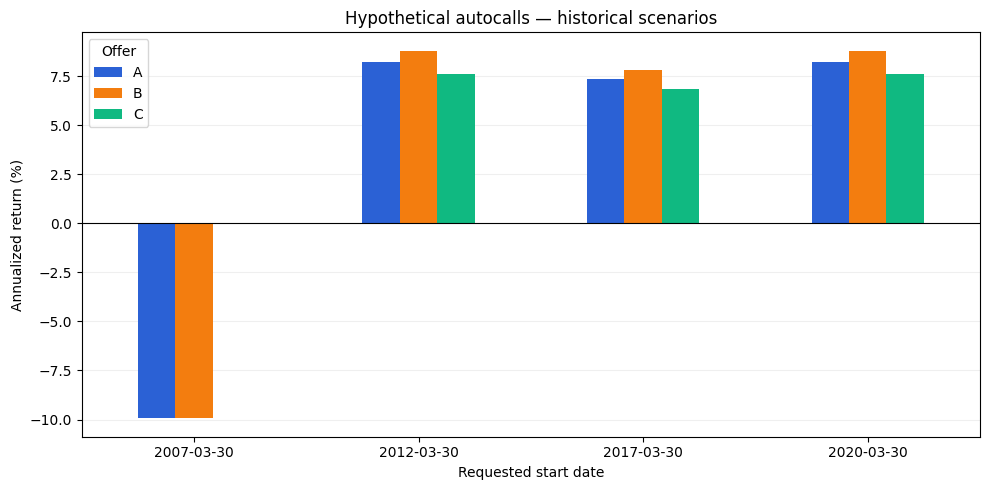

In [9]:
import matplotlib.pyplot as plt

ax = (returns_table * 100).plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2B61D5", "#F37D0F", "#10B981"],
    rot=0,
)

ax.set_title("Hypothetical autocalls — historical scenarios")
ax.set_xlabel("Requested start date")
ax.set_ylabel("Annualized return (%)")
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(title="Offer")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [10]:
monthly_starts = pd.date_range(
    start=prices.index[0],
    end=prices.index[-1] - pd.DateOffset(years=5),
    freq="MS",
)

monthly_results = []

for date in monthly_starts:
    start = date.strftime("%Y-%m-%d")
    levels = build_historical_levels(prices, start)

    for name, terms in historical_offers.items():
        result = evaluate_autocall(
            levels=levels,
            nominal=1000,
            coupon_rate=terms["coupon_rate"],
            autocall_barrier=terms["autocall_barrier"],
            protection_barrier=terms["protection_barrier"],
        )

        monthly_results.append({
            "requested_start": start,
            "offer": name,
            **result,
        })

monthly_comparison = pd.DataFrame(monthly_results)

print(f"Number of starting dates: {len(monthly_starts)}")
print(f"Number of results: {len(monthly_comparison)}")
display(monthly_comparison.head(6))

Number of starting dates: 165
Number of results: 495


,requested_start,offer,autocall_year,duration,redemption,total_return,annualized_return,outcome
0,2007-04-01,A,NaN,5,597.004463,-0.402996,-0.098023,capital_loss
1,2007-04-01,B,NaN,5,597.004463,-0.402996,-0.098023,capital_loss
2,2007-04-01,C,NaN,5,1000.000000,0.000000,0.000000,protected
3,2007-05-01,A,NaN,5,518.700134,-0.481300,-0.123033,capital_loss
4,2007-05-01,B,NaN,5,518.700134,-0.481300,-0.123033,capital_loss
5,2007-05-01,C,NaN,5,518.700134,-0.481300,-0.123033,capital_loss


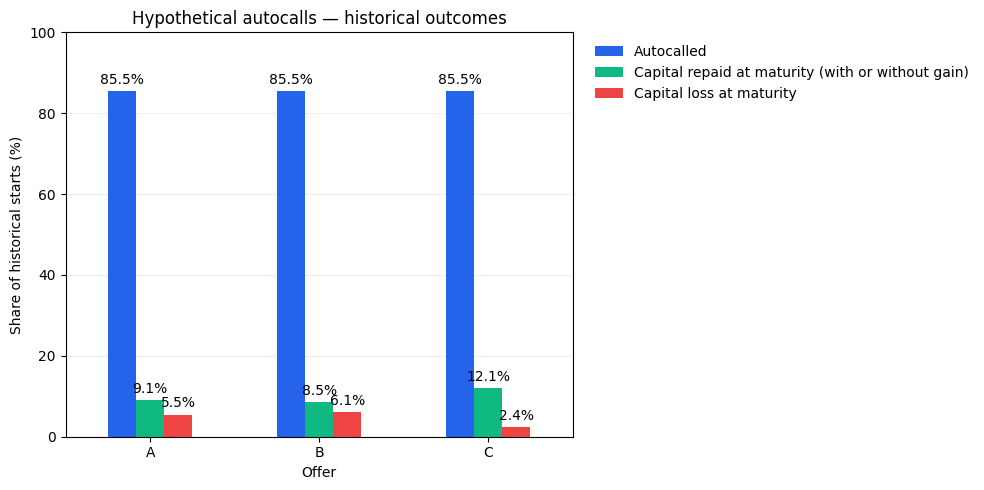

In [11]:
outcome_order = ["autocall", "protected", "capital_loss"]

outcome_frequencies = pd.crosstab(
    monthly_comparison["offer"],
    monthly_comparison["outcome"],
    normalize="index",
).reindex(columns=outcome_order, fill_value=0)

ax = (outcome_frequencies * 100).plot(
    kind="bar",
    figsize=(10, 5),
    color=["#2563EB", "#10B981", "#EF4444"],
    rot=0,
)

ax.set_title("Hypothetical autocalls — historical outcomes")
ax.set_xlabel("Offer")
ax.set_ylabel("Share of historical starts (%)")
ax.set_ylim(0, 100)

ax.legend([
    "Autocalled",
    "Capital repaid at maturity (with or without gain)",
    "Capital loss at maturity",
], loc="upper left", bbox_to_anchor=(1.02, 1), frameon=False,)

ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

## 7. Summary statistics

Summarize historical loss frequency, autocall frequency, returns and effective investment duration.

In [12]:
summary_rows = []

for offer in historical_offers:
    subset = monthly_comparison[monthly_comparison["offer"] == offer]

    summary_rows.append({
        "offer": offer,
        "observations": len(subset),
        "loss_frequency": (subset["total_return"] < 0).mean(),
        "autocall_frequency": subset["autocall_year"].notna().mean(),
        "median_annualized_return": subset["annualized_return"].median(),
        "worst_total_return": subset["total_return"].min(),
        "average_duration": subset["duration"].mean(),
    })

summary = pd.DataFrame(summary_rows).set_index("offer")
display(summary.style.format({
    "observations": "{:.0f}",
    "loss_frequency": "{:.1%}",
    "autocall_frequency": "{:.1%}",
    "median_annualized_return": "{:.2%}",
    "worst_total_return": "{:.2%}",
    "average_duration": "{:.2f}",
}))

,observations,loss_frequency,autocall_frequency,median_annualized_return,worst_total_return,average_duration
offer,,,,,,
A,165,5.5%,85.5%,8.20%,-54.60%,2.16
B,165,6.1%,85.5%,8.80%,-54.60%,2.16
C,165,2.4%,85.5%,7.60%,-54.60%,2.16


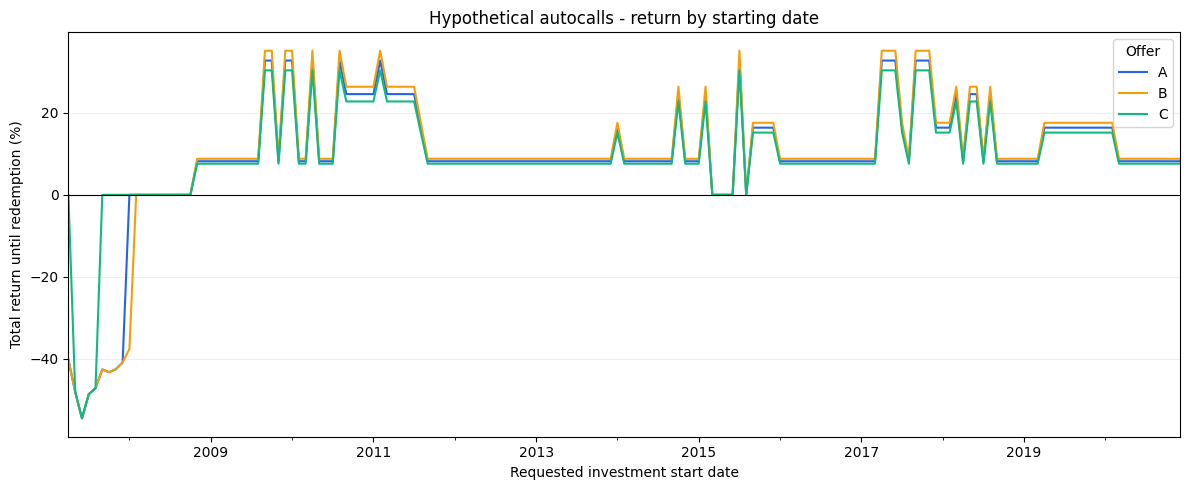

In [13]:
historical_returns = monthly_comparison.pivot(index="requested_start", columns="offer", values="total_return")
historical_returns.index = pd.to_datetime(historical_returns.index)
historical_returns = historical_returns.sort_index()

ax = (historical_returns * 100).plot(
    figsize=(12, 5),
    color=["#2563EB", "#F59E0B", "#10B981"],
    linewidth=1.5,
)

ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Hypothetical autocalls - return by starting date")
ax.set_xlabel("Requested investment start date")
ax.set_ylabel("Total return until redemption (%)")
ax.legend(title="Offer")
ax.grid(axis="y", alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

## 8. Protection trade-off

Identify historical starts where Offer C retained capital protection while Offer B incurred a loss.

In [14]:
protection_cases = historical_returns.loc[(historical_returns["B"] < 0) & (historical_returns["C"] >= 0)]
display(protection_cases.style.format("{:.2%}"))
print(f"Number of matching start: {len(protection_cases)}")

offer,A,B,C
requested_start,,,
2007-04-01 00:00:00,-40.30%,-40.30%,0.00%
2007-09-01 00:00:00,-42.66%,-42.66%,0.00%
2007-10-01 00:00:00,-43.33%,-43.33%,0.00%
2007-11-01 00:00:00,-42.61%,-42.61%,0.00%
2007-12-01 00:00:00,-40.93%,-40.93%,0.00%
2008-01-01 00:00:00,0.00%,-37.67%,0.00%


Number of matching start: 6
